# Experimento multimodal: CNN de imágenes + CNN con atención espectral (STARLIGHT)

Fusiona dos encoders ya validados por separado:

- **Imágenes:** la CNN de `experimento_binario_imagenes_gpu_acc.ipynb` (4 bloques doble `Conv2d`, 32→256 canales, `AdaptiveAvgPool2d`), usada como encoder: produce un vector de 256 y se proyecta a 128.
- **Espectro:** `cnn_attn_control` de `experimento_espectros_starlight_rnn.ipynb` (CNN 1D de 5 etapas stride 2 con pooling por atención enmascarada; ROC-AUC test 0.907 sola) sobre `spectra_cache_starlight` (3600–8900 Å, `FLUX_FoV` modelado).

Los embeddings (128 + 128) se concatenan y pasan a un clasificador MLP de un logit.

**Preguntas:** (1) ¿la fusión mejora a la CNN de imágenes sola? (2) ¿mejora a las fusiones anteriores (ResNet18 + CNN espectral simple)? El historial sugiere que las imágenes dominan (AUC ~0.96) y que añadir espectros no ha ayudado; este experimento prueba si un encoder espectral más fuerte cambia eso.

**Variantes que corre el notebook** (mismo split, cohorte, semilla y protocolo):

| Variante | Descripción |
|---|---|
| `fusion` | CNN imágenes + CNN-atención espectral, concatenación. |
| `image_only_control` | Solo la CNN de imágenes, con el mismo split y optimización. Es el control justo: la CNN de imágenes original usó otro split (`splits_seed42_obj-label.csv`) y no es comparable punto a punto. |

Se usa `splits_seed42_obj-label_FoV.csv` porque la fusión necesita galaxias con espectro, igual que los demás experimentos multimodales.

In [1]:
from __future__ import annotations

import copy
import json
import random
import sys
import time
from pathlib import Path
from typing import Any, Mapping

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    balanced_accuracy_score,
    f1_score,
    roc_auc_score,
)
from torch import nn
from tqdm.auto import tqdm


def project_root(start: Path = Path.cwd()) -> Path:
    for candidate in (start.resolve(), *start.resolve().parents):
        if (candidate / "src").is_dir() and (candidate / "data").is_dir():
            return candidate
    raise FileNotFoundError("No se encontró la raíz del proyecto.")


ROOT = project_root()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.dataloader.multimodal import build_dataloaders
from src.evaluate import evaluate_binary_classifier

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Proyecto: {ROOT}")
print(f"Dispositivo: {DEVICE}")

/home/albertor/Documents/deep_learning/repos/clasificacion-galaxias/.venv/lib64/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Proyecto: /home/albertor/Documents/deep_learning/repos/clasificacion-galaxias
Dispositivo: cuda


## Configuración e invariantes

- Split fijo `splits_seed42_obj-label_FoV.csv`; no se regenera.
- Checkpoint, early stopping y elección de época solo con validación; `test` se evalúa una vez por variante.
- Optimización de la CNN de imágenes (`lr=3e-4`, `clip=1.0`, paciencia 8). El *gradient clipping* se aplica a todas las variantes.
- Una salida logit y `BCEWithLogitsLoss`.

In [2]:
CONFIG: dict[str, Any] = {
    "experiment_group": "multimodal_imagenes_espectros_starlight_cnnattn",
    "seed": 42,
    "data": {
        "project_root": ROOT,
        "manifest": "data/galaxy_manifest.csv",
        "splits": "data/processed/splits_seed42_obj-label_FoV.csv",
        "modalities": ["image", "spectrum"],
        "image": {"fov_column": "fov_0", "size": 256, "normalization": "none"},
        "spectrum": {"cache_dir": "data/processed/spectra/spectra_cache_starlight"},
    },
    "model": {
        "image_embedding_dim": 128,
        "spectrum_embedding_dim": 128,
        "classifier_hidden_dim": 128,
        "dropout": 0.3,
    },
    "training": {
        "batch_size": 32,
        "num_workers": 0,
        "pin_memory": DEVICE.type == "cuda",
        "epochs": 50,
        "learning_rate": 3e-4,
        "weight_decay": 1e-4,
        "max_grad_norm": 1.0,
        "early_stopping_patience": 8,
    },
    "selection_metric": "roc_auc",
}
VARIANTS = ["fusion", "image_only_control"]
EXPERIMENTS_DIR = ROOT / "models" / "experiments"
REFERENCES = {
    "multimodal_imagenes_espectros_starlight_concat": "ResNet18 + CNN1D simple (fusión previa)",
    "imagenes_resnet18_fov": "ResNet18 solo imágenes",
    "espectros_starlight_cnn_attn_control": "CNN-atención solo espectro",
}


def run_dir(variant: str) -> Path:
    return EXPERIMENTS_DIR / f"multimodal_imagenes_espectros_starlight_cnnattn_{variant}"


def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed(CONFIG["seed"])
train_loader, validation_loader, test_loader = build_dataloaders(CONFIG)
for split_name, loader in {"train": train_loader, "validation": validation_loader, "test": test_loader}.items():
    labels = loader.dataset.frame["label"].value_counts()
    print(f"{split_name:10s} n={len(loader.dataset):5d}  temprana={labels.get('temprana', 0):5d}  tardia={labels.get('tardia', 0):5d}")

sample_batch = next(iter(train_loader))
for key, value in sample_batch.items():
    print(f"{key:16s} {tuple(value.shape) if isinstance(value, torch.Tensor) else type(value).__name__}")

train      n= 6545  temprana= 2467  tardia= 4078
validation n= 1403  temprana=  529  tardia=  874
test       n= 1403  temprana=  528  tardia=  875
id               list
label            (32,)
image            (32, 3, 256, 256)
spectrum         (32, 1, 4096)
spectrum_mask    (32, 4096)


## Arquitectura

- `ImageCNNEncoder`: los cuatro bloques de la CNN de imágenes original; `AdaptiveAvgPool2d` + proyección a 128.
- `SpectrumAttentionEncoder`: `cnn_attn_control` tal cual (kernel 7, 4096→128 tokens, atención enmascarada), proyectado a 128. La máscara se propaga por las convoluciones y el softmax ignora los tokens fuera de cobertura.
- `FusionClassifier`: concatenación + MLP. `ImageOnlyClassifier` reutiliza el mismo encoder de imagen y el mismo clasificador con embedding de 128, de modo que el control difiere **solo** en que no recibe el espectro.

In [3]:
class ImageCNNEncoder(nn.Module):
    def __init__(self, embedding_dim: int, dropout: float) -> None:
        super().__init__()

        def conv_block(in_channels: int, out_channels: int) -> nn.Sequential:
            return nn.Sequential(
                nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
                nn.BatchNorm2d(out_channels),
                nn.ReLU(inplace=True),
                nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
                nn.BatchNorm2d(out_channels),
                nn.ReLU(inplace=True),
                nn.MaxPool2d(kernel_size=2),
            )

        self.features = nn.Sequential(conv_block(3, 32), conv_block(32, 64), conv_block(64, 128), conv_block(128, 256))
        self.projection = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(256, embedding_dim),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
        )

    def forward(self, image: torch.Tensor) -> torch.Tensor:
        return self.projection(self.features(image))


class ConvTokenizer(nn.Module):
    """Convoluciones con stride 2; propaga la máscara y anula el relleno en cada etapa."""

    def __init__(self, channels: tuple[int, ...], kernel: int) -> None:
        super().__init__()
        self.kernel = kernel
        self.blocks = nn.ModuleList(
            [
                nn.Sequential(
                    nn.Conv1d(a, b, kernel_size=kernel, stride=2, padding=kernel // 2),
                    nn.BatchNorm1d(b),
                    nn.GELU(),
                )
                for a, b in zip(channels[:-1], channels[1:])
            ]
        )

    def forward(self, spectrum: torch.Tensor, mask: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
        mask = mask.bool()
        for block in self.blocks:
            spectrum = block(spectrum)
            mask = F.max_pool1d(mask.float().unsqueeze(1), self.kernel, stride=2, padding=self.kernel // 2).squeeze(1).bool()
            spectrum = spectrum * mask.unsqueeze(1)
        return spectrum.transpose(1, 2), mask  # [B, T, D], [B, T]


class SpectrumAttentionEncoder(nn.Module):
    def __init__(self, in_channels: int, embedding_dim: int, dropout: float) -> None:
        super().__init__()
        self.tokenizer = ConvTokenizer((in_channels, 32, 64, 128, 128, 256), kernel=7)  # 4096 -> 128 tokens
        self.score = nn.Linear(256, 1)
        self.projection = nn.Sequential(nn.Linear(256, embedding_dim), nn.ReLU(inplace=True), nn.Dropout(dropout))

    def forward(self, spectrum: torch.Tensor, mask: torch.Tensor) -> torch.Tensor:
        if spectrum.ndim != 3 or mask.shape != spectrum.shape[:1] + spectrum.shape[2:]:
            raise ValueError("Se esperaba spectrum=[B, C, L] y spectrum_mask=[B, L].")
        mask = mask.bool()
        tokens, token_mask = self.tokenizer(spectrum * mask.unsqueeze(1), mask)
        scores = self.score(tokens).squeeze(-1).masked_fill(~token_mask, float("-inf"))
        weights = torch.softmax(scores, dim=1).nan_to_num(0.0)
        return self.projection((weights.unsqueeze(-1) * tokens).sum(dim=1))


def mlp_head(in_dim: int, cfg: Mapping[str, Any]) -> nn.Sequential:
    return nn.Sequential(
        nn.Linear(in_dim, int(cfg["classifier_hidden_dim"])),
        nn.ReLU(inplace=True),
        nn.Dropout(float(cfg["dropout"])),
        nn.Linear(int(cfg["classifier_hidden_dim"]), 1),
    )


class FusionClassifier(nn.Module):
    def __init__(self, spectrum_channels: int, cfg: Mapping[str, Any]) -> None:
        super().__init__()
        p = float(cfg["dropout"])
        self.image_encoder = ImageCNNEncoder(int(cfg["image_embedding_dim"]), p)
        self.spectrum_encoder = SpectrumAttentionEncoder(spectrum_channels, int(cfg["spectrum_embedding_dim"]), p)
        self.classifier = mlp_head(int(cfg["image_embedding_dim"]) + int(cfg["spectrum_embedding_dim"]), cfg)

    def forward(self, batch: Mapping[str, Any]) -> torch.Tensor:
        z = torch.cat(
            (self.image_encoder(batch["image"]), self.spectrum_encoder(batch["spectrum"], batch["spectrum_mask"])),
            dim=1,
        )
        return self.classifier(z).squeeze(1)


class ImageOnlyClassifier(nn.Module):
    def __init__(self, cfg: Mapping[str, Any]) -> None:
        super().__init__()
        self.image_encoder = ImageCNNEncoder(int(cfg["image_embedding_dim"]), float(cfg["dropout"]))
        self.classifier = mlp_head(int(cfg["image_embedding_dim"]), cfg)

    def forward(self, batch: Mapping[str, Any]) -> torch.Tensor:
        return self.classifier(self.image_encoder(batch["image"])).squeeze(1)


def build_model(variant: str, config: Mapping[str, Any], batch: Mapping[str, Any]) -> nn.Module:
    if variant == "fusion":
        return FusionClassifier(batch["spectrum"].shape[1], config["model"])
    if variant == "image_only_control":
        return ImageOnlyClassifier(config["model"])
    raise ValueError(f"Variante desconocida: {variant}")


def move_batch_to_device(batch: Mapping[str, Any], device: torch.device) -> dict[str, Any]:
    return {k: v.to(device, non_blocking=True) if isinstance(v, torch.Tensor) else v for k, v in batch.items()}


# Forward de prueba; el relleno espectral fuera de cobertura no debe afectar la salida
for variant in VARIANTS:
    model = build_model(variant, CONFIG, sample_batch).to(DEVICE).eval()
    batch_dev = move_batch_to_device(sample_batch, DEVICE)
    with torch.no_grad():
        logits = model(batch_dev)
        altered = dict(batch_dev)
        altered["spectrum"] = batch_dev["spectrum"] + 100.0 * (~batch_dev["spectrum_mask"]).unsqueeze(1)
        logits_altered = model(altered)
    assert logits.shape == sample_batch["label"].shape and torch.isfinite(logits).all()
    assert torch.allclose(logits, logits_altered, atol=1e-4), "El relleno espectral afecta la salida."
    print(f"{variant:20s} parámetros={sum(p.numel() for p in model.parameters()):>10,d}  logits={tuple(logits.shape)}  OK")
del model

fusion               parámetros= 1,690,082  logits=(32,)  OK
image_only_control   parámetros= 1,222,753  logits=(32,)  OK


## Entrenamiento y evaluación

Para cada variante se reinicia la semilla y se reconstruyen los loaders. Se guardan `config.json`, `history.csv`, `predictions.csv`, `results.json`, `test_metrics.json` y `best_model.pt` en `models/experiments/multimodal_imagenes_espectros_starlight_cnnattn_<variante>/`.

In [4]:
def logits_from_model(model: nn.Module, batch: Mapping[str, Any]) -> torch.Tensor:
    logits = model(batch)
    if logits.shape != batch["label"].shape:
        raise ValueError(f"El modelo devolvió {tuple(logits.shape)}; se esperaba {tuple(batch['label'].shape)}.")
    if not torch.isfinite(logits).all():
        raise FloatingPointError("El modelo produjo logits no finitos.")
    return logits


def train_epoch(model, loader, optimizer, criterion, device, epoch, total_epochs, max_grad_norm) -> float:
    model.train()
    total_loss = 0.0
    progress = tqdm(loader, desc=f"Epoch {epoch:02d}/{total_epochs}", unit="batch", leave=False)
    for batch in progress:
        batch = move_batch_to_device(batch, device)
        optimizer.zero_grad(set_to_none=True)
        loss = criterion(logits_from_model(model, batch), batch["label"])
        if not torch.isfinite(loss):
            raise FloatingPointError("La pérdida de entrenamiento dejó de ser finita.")
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=max_grad_norm)
        optimizer.step()
        total_loss += loss.item() * batch["label"].numel()
        progress.set_postfix(train_loss=f"{total_loss / len(loader.dataset):.4f}")
    return total_loss / len(loader.dataset)


@torch.no_grad()
def evaluate_epoch(model, loader, criterion, device):
    model.eval()
    total_loss = 0.0
    all_true, all_pred, all_proba = [], [], []
    for batch in loader:
        batch = move_batch_to_device(batch, device)
        logits = logits_from_model(model, batch)
        total_loss += criterion(logits, batch["label"]).item() * batch["label"].numel()
        probabilities = torch.sigmoid(logits)
        all_true.append(batch["label"].cpu().numpy())
        all_pred.append((probabilities >= 0.5).to(torch.int64).cpu().numpy())
        all_proba.append(probabilities.cpu().numpy())
    return total_loss / len(loader.dataset), np.concatenate(all_true), np.concatenate(all_pred), np.concatenate(all_proba)


def fit(model, train_loader, validation_loader, config, device, checkpoint_path: Path) -> pd.DataFrame:
    tc = config["training"]
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=tc["learning_rate"], weight_decay=tc["weight_decay"])
    history: list[dict[str, float]] = []
    best_score, best_state, stale = float("-inf"), None, 0

    for epoch in range(1, tc["epochs"] + 1):
        started_at = time.perf_counter()
        train_loss = train_epoch(model, train_loader, optimizer, criterion, device, epoch, tc["epochs"], tc["max_grad_norm"])
        val_loss, y_true, y_pred, y_proba = evaluate_epoch(model, validation_loader, criterion, device)
        metrics = evaluate_binary_classifier(y_true, y_pred, y_proba)
        score = float(metrics[config["selection_metric"]])
        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "validation_loss": val_loss,
            "validation_accuracy": float(metrics["accuracy"]),
            "validation_balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
            "validation_f1": f1_score(y_true, y_pred, zero_division=0),
            "validation_roc_auc": float(metrics["roc_auc"]),
            "seconds": time.perf_counter() - started_at,
        })
        print(f"[{epoch:02d}/{tc['epochs']}] train_loss={train_loss:.4f} val_loss={val_loss:.4f} val_auc={metrics['roc_auc']:.4f}")
        if score > best_score:
            best_score, best_state, stale = score, copy.deepcopy(model.state_dict()), 0
        else:
            stale += 1
            if stale >= tc["early_stopping_patience"]:
                print("Early stopping por validación.")
                break

    if best_state is None:
        raise RuntimeError("No se obtuvo un checkpoint de validación.")
    checkpoint_path.parent.mkdir(parents=True, exist_ok=True)
    model.load_state_dict(best_state)
    torch.save({"model_state_dict": best_state}, checkpoint_path)
    return pd.DataFrame(history)


def to_jsonable(value: Any) -> Any:
    if isinstance(value, Path):
        return str(value)
    if isinstance(value, np.ndarray):
        return value.tolist()
    if isinstance(value, np.generic):
        return value.item()
    if isinstance(value, Mapping):
        return {str(k): to_jsonable(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [to_jsonable(v) for v in value]
    return value


@torch.no_grad()
def predict_split(model, dataset, split_name: str) -> pd.DataFrame:
    loader = torch.utils.data.DataLoader(
        dataset, batch_size=CONFIG["training"]["batch_size"], shuffle=False,
        num_workers=CONFIG["training"]["num_workers"], pin_memory=CONFIG["training"]["pin_memory"],
    )
    model.eval()
    frames = []
    for batch in tqdm(loader, desc=f"Predict {split_name}", unit="batch", leave=False):
        labels = batch["label"].to(torch.int64).numpy()
        probas = torch.sigmoid(model(move_batch_to_device(batch, DEVICE))).cpu().numpy().astype(np.float64)
        frames.append(pd.DataFrame({
            "name": list(batch["id"]), "split": split_name, "y_true": labels,
            "y_proba": probas, "y_pred": (probas >= 0.5).astype(np.int64),
        }))
    return pd.concat(frames, ignore_index=True)


def run_variant(variant: str) -> dict[str, Any]:
    out = run_dir(variant)
    out.mkdir(parents=True, exist_ok=True)
    name = f"multimodal_imagenes_espectros_starlight_cnnattn_{variant}"
    config = {**CONFIG, "experiment_name": name, "variant": variant}
    if variant == "image_only_control":
        config["data"] = {**CONFIG["data"], "modalities": ["image"]}

    set_seed(CONFIG["seed"])
    tr, va, te = build_dataloaders(config)
    model = build_model(variant, config, next(iter(tr))).to(DEVICE)
    n_params = sum(p.numel() for p in model.parameters())
    print(f"\n===== {variant} ({n_params:,d} parámetros) =====")

    started = time.perf_counter()
    history = fit(model, tr, va, config, DEVICE, out / "best_model.pt")
    train_seconds = time.perf_counter() - started

    test_loss, y_true, y_pred, y_proba = evaluate_epoch(model, te, nn.BCEWithLogitsLoss(), DEVICE)
    metrics = evaluate_binary_classifier(y_true, y_pred, y_proba)
    print(f"{variant}: test_loss={test_loss:.4f} acc={metrics['accuracy']:.4f} auc={metrics['roc_auc']:.4f}")

    predictions = pd.concat(
        [predict_split(model, loader.dataset, split) for split, loader in {"train": tr, "validation": va, "test": te}.items()],
        ignore_index=True,
    )
    int_to_label = {0: "temprana", 1: "tardia"}
    predictions["label"] = predictions["y_true"].map(int_to_label)
    predictions["pred_label"] = predictions["y_pred"].map(int_to_label)
    predictions["correct"] = predictions["y_true"] == predictions["y_pred"]
    predictions = predictions[["name", "split", "label", "y_true", "y_proba", "y_pred", "pred_label", "correct"]]

    results = {"test_loss": test_loss, **metrics}
    (out / "config.json").write_text(json.dumps(to_jsonable(config), indent=2), encoding="utf-8")
    (out / "results.json").write_text(json.dumps(to_jsonable(results), indent=2), encoding="utf-8")
    (out / "test_metrics.json").write_text(json.dumps(to_jsonable(results), indent=2), encoding="utf-8")
    history.to_csv(out / "history.csv", index=False)
    predictions.to_csv(out / "predictions.csv", index=False)
    return {
        "variant": variant, "name": name, "parameters": n_params,
        "best_epoch": int(history["validation_roc_auc"].idxmax()) + 1, "epochs_run": len(history),
        "train_seconds": train_seconds, "history": history, "predictions": predictions,
        "metrics": metrics, "test_loss": test_loss,
    }

### Variante 1: fusión imagen + espectro

In [5]:
RUNS: dict[str, dict[str, Any]] = {}
RUNS["fusion"] = run_variant("fusion")


===== fusion (1,690,082 parámetros) =====


[01/50] train_loss=0.4358 val_loss=0.3611 val_auc=0.9193


[02/50] train_loss=0.3576 val_loss=0.3372 val_auc=0.9296


[03/50] train_loss=0.3397 val_loss=0.3166 val_auc=0.9377


[04/50] train_loss=0.3201 val_loss=0.3202 val_auc=0.9409


[05/50] train_loss=0.3168 val_loss=0.4028 val_auc=0.9290


... (3 outputs left out)

[09/50] train_loss=0.3055 val_loss=0.3111 val_auc=0.9378


[10/50] train_loss=0.3029 val_loss=0.3575 val_auc=0.9225


[11/50] train_loss=0.2950 val_loss=0.4136 val_auc=0.9364


[12/50] train_loss=0.2959 val_loss=0.3627 val_auc=0.9392
Early stopping por validación.
fusion: test_loss=0.3437 acc=0.8617 auc=0.9334


### Variante 2: control solo imágenes (mismo split y optimización)

In [6]:
RUNS["image_only_control"] = run_variant("image_only_control")


===== image_only_control (1,222,753 parámetros) =====


[01/50] train_loss=0.4461 val_loss=0.5309 val_auc=0.8865


[02/50] train_loss=0.3801 val_loss=0.3555 val_auc=0.9203


[03/50] train_loss=0.3624 val_loss=0.3641 val_auc=0.9301


[04/50] train_loss=0.3489 val_loss=0.3647 val_auc=0.9207


[05/50] train_loss=0.3400 val_loss=0.3377 val_auc=0.9314


... (41 outputs left out)

[47/50] train_loss=0.2425 val_loss=0.2492 val_auc=0.9645


[48/50] train_loss=0.2300 val_loss=0.2967 val_auc=0.9574


[49/50] train_loss=0.2323 val_loss=0.2824 val_auc=0.9627


[50/50] train_loss=0.2321 val_loss=0.2808 val_auc=0.9603
image_only_control: test_loss=0.2489 acc=0.8952 auc=0.9667


## Curvas de entrenamiento

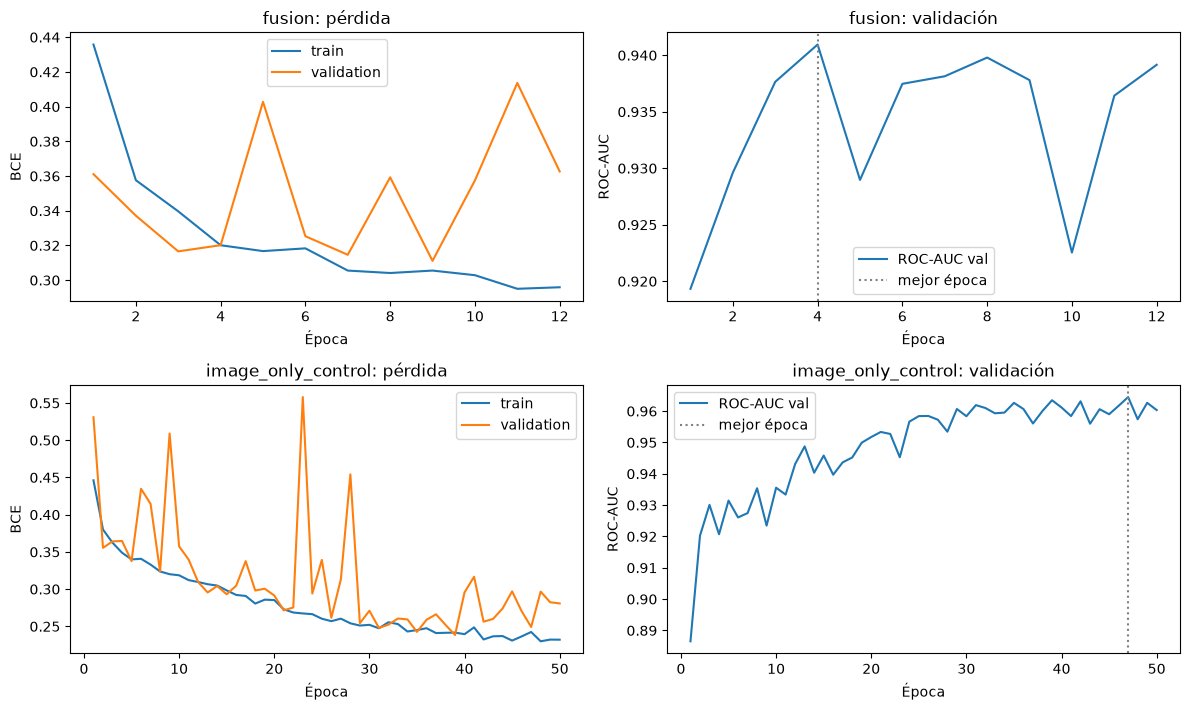

In [7]:
figure, axes = plt.subplots(len(RUNS), 2, figsize=(12, 3.6 * len(RUNS)), squeeze=False)
for row, (variant, run) in enumerate(RUNS.items()):
    h = run["history"]
    axes[row, 0].plot(h["epoch"], h["train_loss"], label="train")
    axes[row, 0].plot(h["epoch"], h["validation_loss"], label="validation")
    axes[row, 0].set(title=f"{variant}: pérdida", xlabel="Época", ylabel="BCE")
    axes[row, 0].legend()
    axes[row, 1].plot(h["epoch"], h["validation_roc_auc"], label="ROC-AUC val")
    axes[row, 1].axvline(run["best_epoch"], color="gray", ls=":", label="mejor época")
    axes[row, 1].set(title=f"{variant}: validación", xlabel="Época", ylabel="ROC-AUC")
    axes[row, 1].legend()
figure.tight_layout()

## Comparación en test

Compara las dos variantes con tres referencias ya entrenadas sobre la **misma cohorte FoV** (se alinean por `name`, no por orden de fila). Los IC95 del AUC son *bootstrap* sobre las galaxias de test. Como todos los modelos se evalúan sobre las mismas galaxias, la diferencia de AUC se estima con *bootstrap pareado*: en cada remuestreo se calculan ambos AUC sobre las mismas galaxias, de modo que el IC de la diferencia es más informativo que comparar intervalos individuales. Si el IC de la diferencia contiene 0, no hay evidencia de mejora.

In [8]:
def test_frame(predictions: pd.DataFrame, column: str) -> pd.DataFrame:
    test = predictions[predictions["split"] == "test"]
    return test.set_index("name")[["y_true", "y_proba"]].rename(columns={"y_proba": column})


def load_reference(experiment: str) -> pd.DataFrame | None:
    path = EXPERIMENTS_DIR / experiment / "predictions.csv"
    return pd.read_csv(path) if path.exists() else None


def bootstrap_auc_ci(y: np.ndarray, p: np.ndarray, n: int = 1000, seed: int = 0) -> tuple[float, float]:
    rng = np.random.default_rng(seed)
    aucs = []
    for _ in range(n):
        idx = rng.integers(0, len(y), len(y))
        if len(np.unique(y[idx])) == 2:
            aucs.append(roc_auc_score(y[idx], p[idx]))
    low, high = np.percentile(aucs, [2.5, 97.5])
    return float(low), float(high)


def paired_auc_diff(y: np.ndarray, p_a: np.ndarray, p_b: np.ndarray, n: int = 1000, seed: int = 0) -> tuple[float, float, float]:
    """AUC(a) - AUC(b) con IC95 por bootstrap pareado."""
    rng = np.random.default_rng(seed)
    diffs = []
    for _ in range(n):
        idx = rng.integers(0, len(y), len(y))
        if len(np.unique(y[idx])) == 2:
            diffs.append(roc_auc_score(y[idx], p_a[idx]) - roc_auc_score(y[idx], p_b[idx]))
    low, high = np.percentile(diffs, [2.5, 97.5])
    return float(roc_auc_score(y, p_a) - roc_auc_score(y, p_b)), float(low), float(high)


models_test = {variant: test_frame(run["predictions"], variant) for variant, run in RUNS.items()}
for experiment, label in REFERENCES.items():
    reference = load_reference(experiment)
    if reference is None:
        print(f"Referencia ausente, se omite: {experiment}")
        continue
    models_test[experiment] = test_frame(reference, experiment)

joined = pd.concat([models_test[k].drop(columns="y_true") if i else models_test[k] for i, k in enumerate(models_test)], axis=1, join="inner")
print(f"Galaxias de test comunes a todos los modelos: {len(joined)}")
y_common = joined["y_true"].to_numpy().astype(int)

rows = []
for key in models_test:
    p = joined[key].to_numpy()
    low, high = bootstrap_auc_ci(y_common, p)
    pred = (p >= 0.5).astype(int)
    rows.append({
        "modelo": RUNS[key]["variant"] if key in RUNS else REFERENCES[key],
        "origen": "este notebook" if key in RUNS else "referencia",
        "accuracy": float((pred == y_common).mean()),
        "balanced_acc": balanced_accuracy_score(y_common, pred),
        "f1 tardía": f1_score(y_common, pred, zero_division=0),
        "roc_auc": roc_auc_score(y_common, p),
        "IC95 auc": f"[{low:.3f}, {high:.3f}]",
    })
comparison = pd.DataFrame(rows).sort_values("roc_auc", ascending=False)
comparison.to_csv(EXPERIMENTS_DIR / "multimodal_imagenes_espectros_starlight_cnnattn_comparison.csv", index=False)
comparison.round(4)

Galaxias de test comunes a todos los modelos: 1403


,modelo,origen,accuracy,balanced_acc,f1 tardía,roc_auc,IC95 auc
1,image_only_control,este notebook,0.8952,0.8980,0.9135,0.9667,"[0.959, 0.975]"
3,ResNet18 solo imágenes,referencia,0.8881,0.8825,0.9098,0.9633,"[0.955, 0.972]"
2,ResNet18 + CNN1D simple (fusión previa),referencia,0.8931,0.8925,0.9126,0.9632,"[0.955, 0.971]"
0,fusion,este notebook,0.8617,0.8696,0.8831,0.9334,"[0.920, 0.946]"
4,CNN-atención solo espectro,referencia,0.8418,0.8360,0.8714,0.9066,"[0.890, 0.922]"


In [9]:
fusion_p = joined["fusion"].to_numpy()
diff_rows = []
for key in models_test:
    if key == "fusion":
        continue
    d, lo, hi = paired_auc_diff(y_common, fusion_p, joined[key].to_numpy())
    diff_rows.append({
        "fusion menos": RUNS[key]["variant"] if key in RUNS else REFERENCES[key],
        "ΔAUC": d, "IC95 ΔAUC": f"[{lo:.4f}, {hi:.4f}]", "excluye 0": bool(lo > 0 or hi < 0),
    })
pd.DataFrame(diff_rows).round(4)

,fusion menos,ΔAUC,IC95 ΔAUC,excluye 0
0,image_only_control,-0.0333,"[-0.0447, -0.0227]",True
1,ResNet18 + CNN1D simple (fusión previa),-0.0298,"[-0.0401, -0.0203]",True
2,ResNet18 solo imágenes,-0.0299,"[-0.0413, -0.0189]",True
3,CNN-atención solo espectro,0.0268,"[0.0139, 0.0393]",True


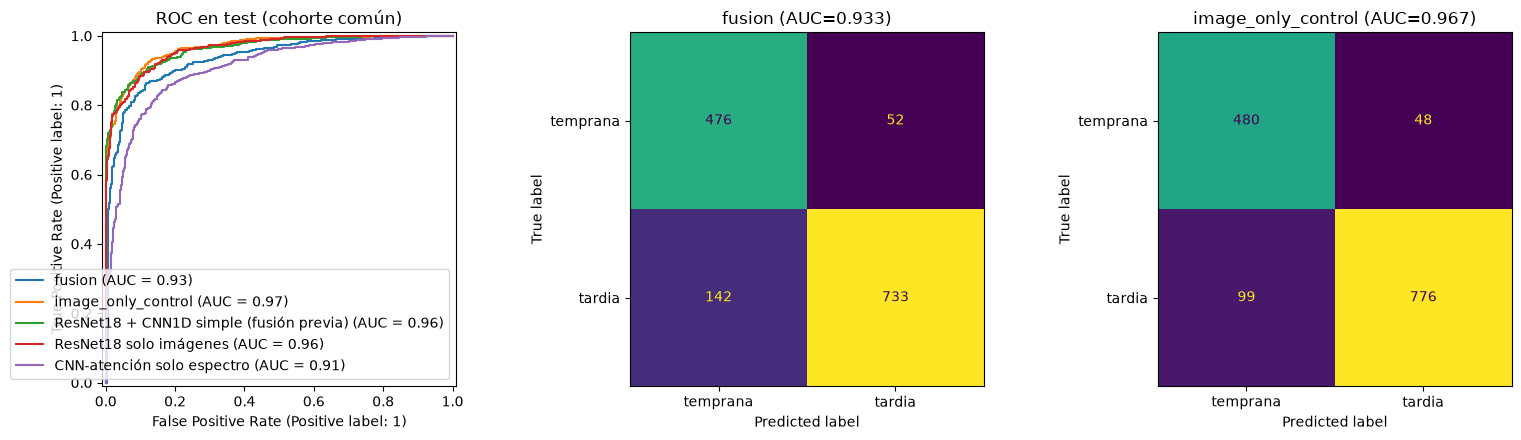

In [10]:
figure, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for key in models_test:
    RocCurveDisplay.from_predictions(
        y_common, joined[key].to_numpy(), ax=axes[0],
        name=RUNS[key]["variant"] if key in RUNS else REFERENCES[key],
    )
axes[0].set_title("ROC en test (cohorte común)")
for ax, (variant, run) in zip(axes[1:], RUNS.items()):
    ConfusionMatrixDisplay(
        confusion_matrix=run["metrics"]["confusion_matrix"], display_labels=["temprana", "tardia"]
    ).plot(ax=ax, colorbar=False)
    ax.set_title(f"{variant} (AUC={run['metrics']['roc_auc']:.3f})")
figure.tight_layout()

## Interpretación

Completar tras ejecutar:

1. ¿`fusion` supera a `image_only_control`? Mirar el IC95 de ΔAUC, no solo el valor puntual. Si incluye 0, el espectro no aporta información utilizable a esta arquitectura.
2. ¿`fusion` supera a la fusión previa (ResNet18 + CNN1D simple) y a ResNet18 sola? Ojo: las referencias usan otra arquitectura de imagen y otro lr, por lo que ese contraste mezcla efectos; el control `image_only_control` es la comparación limpia.
3. Si no hay mejora: las imágenes ya contienen la información espectral relevante para la morfología (el espectro integrado FoV es un resumen de la galaxia) o la concatenación simple no la aprovecha; las siguientes opciones serían *gated fusion* o *late fusion* de probabilidades (guía 9.5) y el análisis de errores discordantes.

Limitaciones: una semilla, un split; el espectro es el modelo ajustado de STARLIGHT derivado de FoV, no el observado (guía 22.6); la fusión se entrena de extremo a extremo desde cero, y con dos encoders de ritmos de aprendizaje distintos una modalidad puede dominar (guía 22.4).